In [34]:
# Versão para Atividade 4
import geopandas as gpd
import numpy as np
import random
import matplotlib.pyplot as plt

from shapely.geometry import Polygon

# Importa e reprojeta os arquivos
area_interesse = gpd.read_file('PEmSE/area_interesse.shp').to_crs('EPSG:3857')
passagem_SAR = gpd.read_file('PEmSE/passagens_SAR.shp').to_crs('EPSG:3857')

# Calcula a área em km2 segundo a projeção definida
area_interesse['area_km2'] = area_interesse.to_crs('EPSG:3857').geometry.area / 1000000
passagem_SAR['area_km2'] = passagem_SAR.to_crs('EPSG:3857').geometry.area / 1000000

print(f"Number of passages: {len(passagem_SAR)}")

def evaluate_flexible_passagens(individual, selected_passagens_indices):
    selected_passagens_indices = [i for i, val in enumerate(individual) if val]
    selected_passagens = passagem_SAR.iloc[selected_passagens_indices]

    if selected_passagens.empty:
        return 0  # Return 0 if no passages are selected

    intersecao = gpd.overlay(area_interesse, selected_passagens, how='intersection')

    # Calcula area em km2 para as faixas selecionadas
    area_intersections = intersecao
    area_intersections['area_km2'] = area_intersections.geometry.area / 1000000
    #area_intersection_sum = area_intersections['area_km2'].sum() - dava warning - abaixo corrigido
    area_intersection_sum = area_intersections['area_km2'].sum(numeric_only=True)

    # Calcula area em km2 para as faixas selecionadas (eliminando sobreposicao)
    uniao = intersecao.geometry.union_all()
    area_uniao = uniao.area / 1000000  # Area in km²

     # Sobreposição
    overlap = (area_intersection_sum - area_uniao)/(area_intersection_sum + area_uniao)

    #area_total = area_interesse.sum()
    area_covered = area_uniao / area_interesse['area_km2'].sum()
    passages = len(selected_passagens)/len(passagem_SAR)

    overlap2 = (area_intersection_sum - area_uniao)
    area_covered2 = area_uniao
    passages2 = len(selected_passagens)

    w1=1
    w2=1.5#2
    w3=0.5#1


    score = (w1*area_covered - w2*passages - w3*overlap)

    print(f"Área coberta (AC): {area_covered}",
          f"Número de passagens : {passages2}",
           f"sobreposição: {overlap}",
          f"Score: {score}")


    return score

print(area_interesse)

print(area_interesse.sum(numeric_only=True))

Number of passages: 702
   DN  area                                           geometry       area_km2
0   1     3  POLYGON ((-6064650.101 -312930.486, -6052850.3...    3738.925071
1   1     4  POLYGON ((-5351101.095 -365993.039, -5336852.3...   28187.026492
2   1     7  POLYGON ((-5973591.897 -677640.649, -5964909.0...    7564.353656
3   1     8  POLYGON ((-6581833.982 -675625.641, -6572483.2...   39069.397812
4   1    11  POLYGON ((-6355412.972 -1060595.143, -6352296....    7764.852837
5   1    12  POLYGON ((-7080761.696 -770407.192, -7076976.8...  122662.452378
6   1    13  POLYGON ((-6066876.463 -1293839.277, -6064650....    7037.422047
DN               7.000000
area            58.000000
area_km2    216024.430292
dtype: float64


In [2]:
n_passagens = len(passagem_SAR)

print(f"Número de passagens: {n_passagens}")

Número de passagens: 702


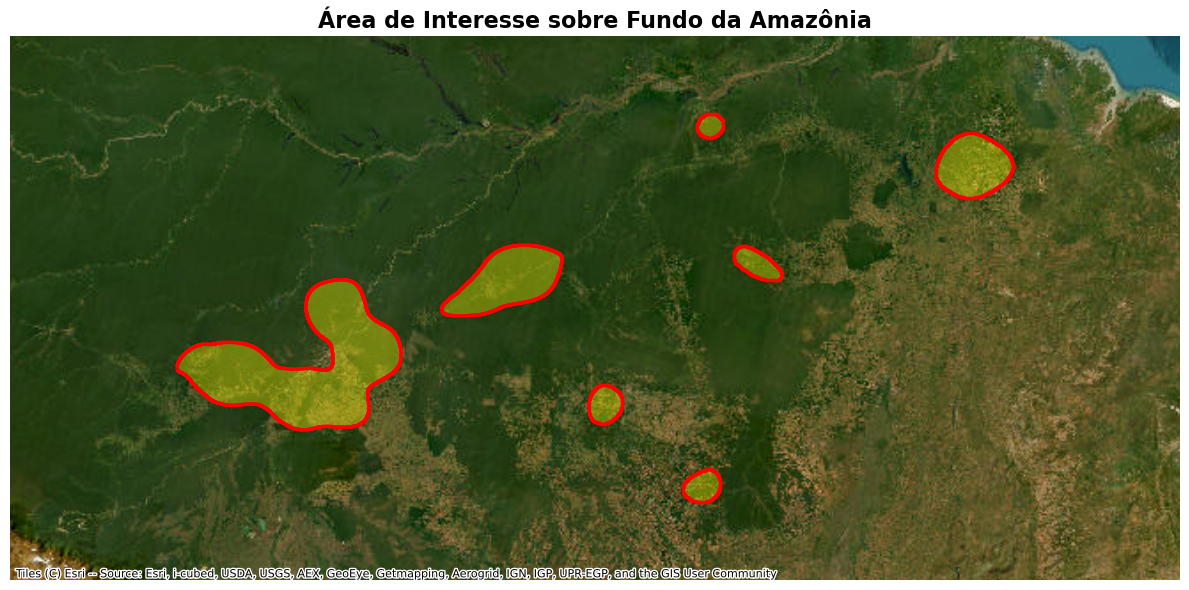

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

# Se ainda não estiver carregado:
# area_interesse = gpd.read_file('/content/drive/MyDrive/PEmSE/area_interesse.shp')

# Reprojetar para o sistema usado pelo mapa-base
area_plot = area_interesse.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Plotar a área de interesse preenchida
area_plot.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='red',
    alpha=0.35,
    linewidth=2.5,
    zorder=2
)

# Opcional: desenhar também só o contorno por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=2.5,
    zorder=3
)

ax.set_title('Área de Interesse sobre Fundo da Amazônia', fontsize=16, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('area_interesse_amazonia_fundo.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
# Cria uma solução aleatória para o problema
n_passagens = len(passagem_SAR)
individual = np.random.randint(0, 2, size=n_passagens)

# Mostra o tamanho da solução e quantas passagens foram escolhidas
print(f"Tamanho do indivíduo: {len(individual)}")
print(f"Passagens selecionadas: {np.sum(individual)}")

Tamanho do indivíduo: 702
Passagens selecionadas: 367


In [30]:
# Define o tamanho da população
tamanho_populacao = 10

# Cria várias soluções aleatórias
populacao = [
    np.random.randint(0, 2, size=n_passagens)
    for _ in range(tamanho_populacao)
]

# Mostra quantas soluções foram criadas
print(f"Tamanho da população: {len(populacao)}")
print(f"Tamanho de cada indivíduo: {len(populacao[0])}")

Tamanho da população: 10
Tamanho de cada indivíduo: 702


In [6]:
# Mostra quantas passagens foram selecionadas em cada solução
for i, individual in enumerate(populacao):
    print(f"Indivíduo {i + 1}: {np.sum(individual)} passagens selecionadas")

Indivíduo 1: 339 passagens selecionadas
Indivíduo 2: 346 passagens selecionadas
Indivíduo 3: 339 passagens selecionadas
Indivíduo 4: 340 passagens selecionadas
Indivíduo 5: 372 passagens selecionadas
Indivíduo 6: 366 passagens selecionadas
Indivíduo 7: 359 passagens selecionadas
Indivíduo 8: 329 passagens selecionadas
Indivíduo 9: 326 passagens selecionadas
Indivíduo 10: 363 passagens selecionadas


In [7]:
def evaluate_passagens(individual):

    # Identifica as passagens selecionadas
    indices = [i for i, valor in enumerate(individual) if valor]
    selected_passagens = passagem_SAR.iloc[indices]

    # Retorna zero se nenhuma passagem foi selecionada
    if selected_passagens.empty:
        return 0

    # Calcula a interseção das passagens com a área de interesse
    intersecao = gpd.overlay(
        area_interesse,
        selected_passagens,
        how='intersection'
    )

    # Calcula a soma das áreas de interseção
    area_intersections = intersecao.geometry.area.sum() / 1000000

    # Calcula a área total coberta, sem contar as sobreposições
    uniao = intersecao.geometry.union_all()
    area_uniao = uniao.area / 1000000

    # Calcula as métricas da solução
    overlap = (area_intersections - area_uniao) / (area_intersections + area_uniao)
    area_covered = area_uniao / area_interesse['area_km2'].sum()
    passages = len(selected_passagens) / len(passagem_SAR)

    # Define os pesos da função objetivo
    w1 = 1
    w2 = 1.5
    w3 = 0.5

    # Calcula o score da solução
    score = w1 * area_covered - w2 * passages - w3 * overlap

    return score

In [8]:
# Avalia cada indivíduo da população
scores = [evaluate_passagens(individual) for individual in populacao]

# Mostra o resultado de cada solução
for i, score in enumerate(scores):
    print(f"Indivíduo {i + 1}: Score = {score:.6f}")

Indivíduo 1: Score = -0.087499
Indivíduo 2: Score = -0.109390
Indivíduo 3: Score = -0.109339
Indivíduo 4: Score = -0.092564
Indivíduo 5: Score = -0.169688
Indivíduo 6: Score = -0.173859
Indivíduo 7: Score = -0.137193
Indivíduo 8: Score = -0.067253
Indivíduo 9: Score = -0.059360
Indivíduo 10: Score = -0.153471


In [9]:
# Transforma os scores em valores positivos
fitness = scores - np.min(scores) + 1e-10

# Calcula a probabilidade de seleção de cada indivíduo
probabilidades = fitness / np.sum(fitness)

# Mostra as probabilidades
for i, prob in enumerate(probabilidades):
    print(f"Indivíduo {i + 1}: {prob:.4f}")

Indivíduo 1: 0.1492
Indivíduo 2: 0.1113
Indivíduo 3: 0.1114
Indivíduo 4: 0.1404
Indivíduo 5: 0.0072
Indivíduo 6: 0.0000
Indivíduo 7: 0.0633
Indivíduo 8: 0.1841
Indivíduo 9: 0.1978
Indivíduo 10: 0.0352


In [10]:
# Seleciona indivíduos de acordo com suas probabilidades
indices_selecionados = np.random.choice(
    len(populacao),
    size=tamanho_populacao,
    replace=True,
    p=probabilidades
)

# Cria a população selecionada
populacao_selecionada = [
    populacao[i].copy() for i in indices_selecionados
]

print(f"Indivíduos selecionados: {len(populacao_selecionada)}")

Indivíduos selecionados: 10


In [11]:
# Combina dois indivíduos para gerar dois filhos
def cruzamento(pai1, pai2):
    ponto = np.random.randint(1, n_passagens)

    filho1 = np.concatenate((pai1[:ponto], pai2[ponto:]))
    filho2 = np.concatenate((pai2[:ponto], pai1[ponto:]))

    return filho1, filho2

In [12]:
# Forma uma nova população combinando os indivíduos selecionados
nova_populacao = []

for i in range(0, tamanho_populacao, 2):
    pai1 = populacao_selecionada[i]
    pai2 = populacao_selecionada[i + 1]

    filho1, filho2 = cruzamento(pai1, pai2)

    nova_populacao.append(filho1)
    nova_populacao.append(filho2)

print(f"Indivíduos após o cruzamento: {len(nova_populacao)}")

Indivíduos após o cruzamento: 10


In [13]:
taxa_mutacao = 0.01

# Altera alguns genes aleatoriamente
def mutacao(individual, taxa_mutacao):
    mascara = np.random.rand(len(individual)) < taxa_mutacao
    individual[mascara] = 1 - individual[mascara]

    return individual

In [14]:
# Aplica a mutação em cada indivíduo da nova população
for individual in nova_populacao:
    mutacao(individual, taxa_mutacao)

print(f"Indivíduos após a mutação: {len(nova_populacao)}")

Indivíduos após a mutação: 10


In [15]:
# Avalia os indivíduos depois do cruzamento e da mutação
novos_scores = [
    evaluate_passagens(individual)
    for individual in nova_populacao
]

# Mostra o resultado de cada indivíduo
for i, score in enumerate(novos_scores):
    print(f"Indivíduo {i + 1}: Score = {score:.6f}")

Indivíduo 1: Score = -0.082912
Indivíduo 2: Score = -0.060863
Indivíduo 3: Score = -0.072091
Indivíduo 4: Score = -0.119498
Indivíduo 5: Score = -0.095486
Indivíduo 6: Score = -0.074545
Indivíduo 7: Score = -0.136602
Indivíduo 8: Score = -0.047669
Indivíduo 9: Score = -0.091313
Indivíduo 10: Score = -0.097202


In [16]:
# Identifica o indivíduo com o maior score
melhor_indice = np.argmax(novos_scores)

melhor_individuo = nova_populacao[melhor_indice]
melhor_score = novos_scores[melhor_indice]

print(f"Melhor score: {melhor_score:.6f}")
print(f"Passagens selecionadas: {np.sum(melhor_individuo)}")

Melhor score: -0.047669
Passagens selecionadas: 324


In [17]:
# Preserva o melhor indivíduo da geração atual
melhor_anterior = populacao[np.argmax(scores)].copy()
melhor_score_anterior = max(scores)

# Verifica se o melhor indivíduo da nova população é pior
if melhor_score_anterior > melhor_score:
    pior_indice = np.argmin(novos_scores)

    nova_populacao[pior_indice] = melhor_anterior.copy()
    novos_scores[pior_indice] = melhor_score_anterior

print(f"Melhor score preservado: {max(novos_scores):.6f}")

Melhor score preservado: -0.047669


In [18]:
# Guarda a melhor solução encontrada até agora
melhor_global = melhor_anterior.copy()
melhor_score_global = melhor_score_anterior

if max(novos_scores) > melhor_score_global:
    melhor_indice = np.argmax(novos_scores)
    melhor_global = nova_populacao[melhor_indice].copy()
    melhor_score_global = max(novos_scores)

print(f"Melhor score global: {melhor_score_global:.6f}")

Melhor score global: -0.047669


In [19]:
# Define os parâmetros do algoritmo genético
numero_geracoes = 50
taxa_mutacao = 0.01

# Guarda o melhor resultado de cada geração
historico_scores = []

In [20]:
def executar_ag(tamanho_populacao, numero_geracoes, taxa_mutacao):

    # Cria uma população inicial aleatória
    populacao = [
        np.random.randint(0, 2, size=n_passagens)
        for _ in range(tamanho_populacao)
    ]

    # Inicializa o melhor resultado encontrado
    melhor_global = None
    melhor_score_global = -np.inf
    historico_scores = []

    # Executa o algoritmo genético por várias gerações
    for geracao in range(numero_geracoes):

        # Avalia os indivíduos da população atual
        scores = np.array([
            evaluate_passagens(individual)
            for individual in populacao
        ])

        # Guarda o melhor indivíduo da geração atual
        melhor_indice = np.argmax(scores)
        melhor_individuo = populacao[melhor_indice].copy()
        melhor_score = scores[melhor_indice]

        # Atualiza o melhor resultado global
        if melhor_score > melhor_score_global:
            melhor_global = melhor_individuo.copy()
            melhor_score_global = melhor_score

        # Registra o melhor score global
        historico_scores.append(melhor_score_global)

In [21]:
        # Transforma os scores em valores positivos
        fitness = scores - np.min(scores) + 1e-10
        probabilidades = fitness / np.sum(fitness)

        # Seleciona os indivíduos pela roleta
        indices = np.random.choice(
            len(populacao),
            size=tamanho_populacao,
            replace=True,
            p=probabilidades
        )

        populacao_selecionada = [
            populacao[i].copy() for i in indices
        ]

In [22]:
        # Realiza o cruzamento entre os indivíduos selecionados
        nova_populacao = []

        for i in range(0, tamanho_populacao, 2):
            pai1 = populacao_selecionada[i]
            pai2 = populacao_selecionada[i + 1]

            filho1, filho2 = cruzamento(pai1, pai2)

            nova_populacao.extend([filho1, filho2])

In [23]:
def executar_ag(tamanho_populacao, numero_geracoes, taxa_mutacao):

    # Cria uma população inicial aleatória
    populacao = [
        np.random.randint(0, 2, size=n_passagens)
        for _ in range(tamanho_populacao)
    ]

    # Inicializa o melhor resultado encontrado
    melhor_global = None
    melhor_score_global = -np.inf
    historico_scores = []

    # Executa o algoritmo genético por várias gerações
    for geracao in range(numero_geracoes):

        # Avalia os indivíduos da população atual
        scores = np.array([
            evaluate_passagens(individual)
            for individual in populacao
        ])

        # Guarda o melhor indivíduo da geração atual
        melhor_indice = np.argmax(scores)
        melhor_individuo = populacao[melhor_indice].copy()
        melhor_score = scores[melhor_indice]

        # Atualiza o melhor resultado global
        if melhor_score > melhor_score_global:
            melhor_global = melhor_individuo.copy()
            melhor_score_global = melhor_score

        # Registra o melhor score global
        historico_scores.append(melhor_score_global)

        # Transforma os scores em valores positivos
        fitness = scores - np.min(scores) + 1e-10
        probabilidades = fitness / np.sum(fitness)

        # Seleciona os indivíduos pela roleta
        indices = np.random.choice(
            len(populacao),
            size=tamanho_populacao,
            replace=True,
            p=probabilidades
        )

        populacao_selecionada = [
            populacao[i].copy() for i in indices
        ]

        # Realiza o cruzamento entre os indivíduos selecionados
        nova_populacao = []

        for i in range(0, tamanho_populacao, 2):
            pai1 = populacao_selecionada[i]
            pai2 = populacao_selecionada[i + 1]

            filho1, filho2 = cruzamento(pai1, pai2)

            nova_populacao.extend([filho1, filho2])

        # Aplica a mutação nos novos indivíduos
        for individual in nova_populacao:
            mutacao(individual, taxa_mutacao)

        # Preserva o melhor indivíduo da geração anterior
        scores_novos = np.array([
            evaluate_passagens(individual)
            for individual in nova_populacao
        ])

        pior_indice = np.argmin(scores_novos)
        nova_populacao[pior_indice] = melhor_individuo.copy()

        # Atualiza a população para a próxima geração
        populacao = nova_populacao

        print(
            f"Geração {geracao + 1}: "
            f"Melhor score = {melhor_score_global:.6f}"
        )

    return melhor_global, melhor_score_global, historico_scores

In [24]:
# Grid Search: busca exaustiva que testa todas as combinações possíveis de hiperparâmetros
from itertools import product

# Define os valores dos hiperparâmetros que serão testados
parametros = {
    'tamanho_populacao': [10, 20],
    'numero_geracoes': [20, 30],
    'taxa_mutacao': [0.01, 0.05]
}

# Gera todas as combinações possíveis de hiperparâmetros
combinacoes = list(product(
    parametros['tamanho_populacao'],
    parametros['numero_geracoes'],
    parametros['taxa_mutacao']
))

# Exibe a quantidade de combinações geradas
print(f"Total de combinações: {len(combinacoes)}")

Total de combinações: 8


In [26]:
# Armazena os resultados de cada combinação testada
resultados_grid = []

# Testa cada combinação de hiperparâmetros
for tamanho_populacao, numero_geracoes, taxa_mutacao in combinacoes:

    print(
        f"\nTestando: população={tamanho_populacao}, "
        f"gerações={numero_geracoes}, "
        f"mutação={taxa_mutacao}"
    )

    # Executa o algoritmo genético com os parâmetros atuais
    melhor_individuo, melhor_score, historico = executar_ag(
        tamanho_populacao,
        numero_geracoes,
        taxa_mutacao
    )

    # Armazena os resultados da execução
    resultados_grid.append({
        'tamanho_populacao': tamanho_populacao,
        'numero_geracoes': numero_geracoes,
        'taxa_mutacao': taxa_mutacao,
        'melhor_score': melhor_score,
        'passagens_selecionadas': np.sum(melhor_individuo)
    })


Testando: população=10, gerações=20, mutação=0.01
Geração 1: Melhor score = -0.052195
Geração 2: Melhor score = -0.052195
Geração 3: Melhor score = -0.052195
Geração 4: Melhor score = -0.041526
Geração 5: Melhor score = -0.038210
Geração 6: Melhor score = -0.035318
Geração 7: Melhor score = -0.027290
Geração 8: Melhor score = -0.023793
Geração 9: Melhor score = -0.019365
Geração 10: Melhor score = -0.011948
Geração 11: Melhor score = -0.004672
Geração 12: Melhor score = -0.004218
Geração 13: Melhor score = 0.003150
Geração 14: Melhor score = 0.008360
Geração 15: Melhor score = 0.008700
Geração 16: Melhor score = 0.009779
Geração 17: Melhor score = 0.018869
Geração 18: Melhor score = 0.018869
Geração 19: Melhor score = 0.035954
Geração 20: Melhor score = 0.035954

Testando: população=10, gerações=20, mutação=0.05
Geração 1: Melhor score = -0.058734
Geração 2: Melhor score = -0.032898
Geração 3: Melhor score = -0.032898
Geração 4: Melhor score = -0.032898
Geração 5: Melhor score = 0.000

In [27]:
import pandas as pd

# Organiza os resultados em uma tabela
df_resultados = pd.DataFrame(resultados_grid)

# Ordena do maior para o menor score
df_resultados = df_resultados.sort_values(
    by='melhor_score',
    ascending=False
).reset_index(drop=True)

# Exibe os resultados
display(df_resultados)

,tamanho_populacao,numero_geracoes,taxa_mutacao,melhor_score,passagens_selecionadas
0,20,30,0.01,0.101491,265
1,10,30,0.01,0.101322,268
2,10,30,0.05,0.093095,266
3,20,20,0.01,0.081109,279
4,20,20,0.05,0.060479,278
5,20,30,0.05,0.059361,284
6,10,20,0.05,0.052407,274
7,10,20,0.01,0.035954,287


In [28]:
# Identifica a combinação com o maior score
melhor_resultado = df_resultados.iloc[0]

print("Melhores hiperparâmetros encontrados:")
print(f"População: {melhor_resultado['tamanho_populacao']}")
print(f"Gerações: {melhor_resultado['numero_geracoes']}")
print(f"Taxa de mutação: {melhor_resultado['taxa_mutacao']}")

print(f"\nMelhor score: {melhor_resultado['melhor_score']:.6f}")
print(
    "Passagens selecionadas: "
    f"{int(melhor_resultado['passagens_selecionadas'])}"
)

Melhores hiperparâmetros encontrados:
População: 20.0
Gerações: 30.0
Taxa de mutação: 0.01

Melhor score: 0.101491
Passagens selecionadas: 265


In [29]:
# Utiliza os melhores hiperparâmetros encontrados pelo Grid Search
melhor_populacao = int(melhor_resultado['tamanho_populacao'])
melhor_geracoes = int(melhor_resultado['numero_geracoes'])
melhor_mutacao = melhor_resultado['taxa_mutacao']

# Executa o algoritmo genético com os parâmetros escolhidos
melhor_global, melhor_score_global, historico_scores = executar_ag(
    melhor_populacao,
    melhor_geracoes,
    melhor_mutacao
)

# Exibe os resultados da execução
print(f"Melhor score: {melhor_score_global:.6f}")
print(f"Passagens selecionadas: {np.sum(melhor_global)}")

Geração 1: Melhor score = -0.053896
Geração 2: Melhor score = -0.029033
Geração 3: Melhor score = -0.005306
Geração 4: Melhor score = -0.002004
Geração 5: Melhor score = 0.010255
Geração 6: Melhor score = 0.013221
Geração 7: Melhor score = 0.041236
Geração 8: Melhor score = 0.041236
Geração 9: Melhor score = 0.041236
Geração 10: Melhor score = 0.048309
Geração 11: Melhor score = 0.053629
Geração 12: Melhor score = 0.059622
Geração 13: Melhor score = 0.059622
Geração 14: Melhor score = 0.062862
Geração 15: Melhor score = 0.070904
Geração 16: Melhor score = 0.074018
Geração 17: Melhor score = 0.078212
Geração 18: Melhor score = 0.083313
Geração 19: Melhor score = 0.084515
Geração 20: Melhor score = 0.108800
Geração 21: Melhor score = 0.108800
Geração 22: Melhor score = 0.108800
Geração 23: Melhor score = 0.119673
Geração 24: Melhor score = 0.123895
Geração 25: Melhor score = 0.124640
Geração 26: Melhor score = 0.124640
Geração 27: Melhor score = 0.133679
Geração 28: Melhor score = 0.1336

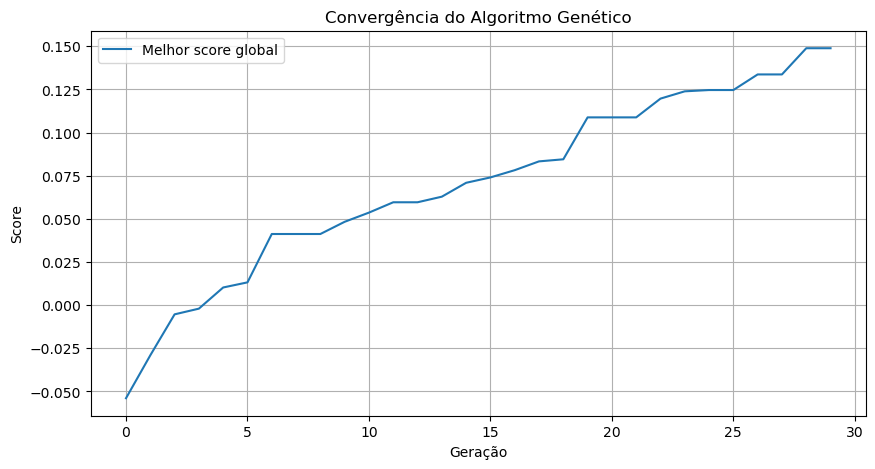

In [31]:
# Mostra como o melhor score evoluiu ao longo das gerações
plt.figure(figsize=(10, 5))

plt.plot(
    historico_scores,
    label='Melhor score global'
)

plt.xlabel('Geração')
plt.ylabel('Score')
plt.title('Convergência do Algoritmo Genético')

plt.legend()
plt.grid()

plt.show()

C:\Users\maria\AppData\Local\Temp\ipykernel_19688\984048062.py:67: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


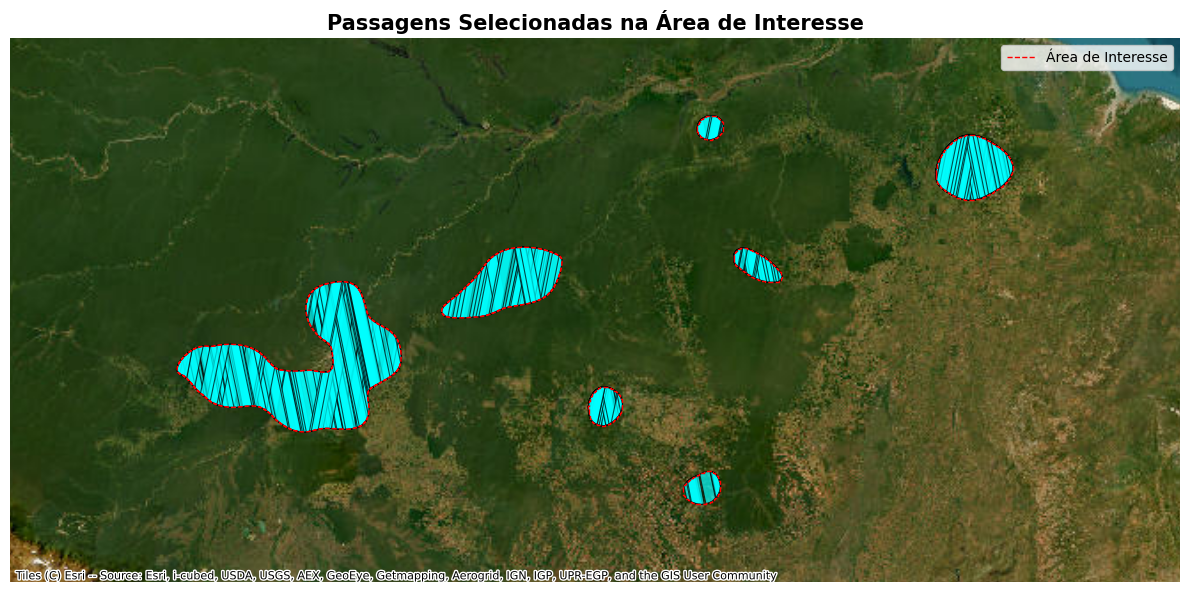

In [32]:
# Identifica as passagens selecionadas pelo algoritmo
indices_selecionados = [
    i for i, valor in enumerate(melhor_global)
    if valor == 1
]

# Seleciona as passagens correspondentes no GeoDataFrame
gdf_otimizado = passagem_SAR.iloc[indices_selecionados].copy()

# Recorta as passagens para mostrar apenas a área de interesse
gdf_recortado = gdf_otimizado.clip(area_interesse)

# Converte os dados para o sistema de coordenadas do mapa base
area_plot = area_interesse.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Cria a figura do mapa
fig, ax = plt.subplots(figsize=(12, 10))

# Define os limites do mapa com uma margem ao redor da área
xmin, ymin, xmax, ymax = area_plot.total_bounds

dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o mapa de satélite como fundo
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Plota as passagens selecionadas
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Passagens Selecionadas'
)

# Destaca o limite da área de interesse
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

# Ajusta os elementos do mapa
ax.set_title(
    'Passagens Selecionadas na Área de Interesse',
    fontsize=15,
    fontweight='bold'
)

ax.legend()
ax.set_axis_off()

plt.tight_layout()

# Salva o mapa em alta resolução
plt.savefig(
    'passagens_otimizadas.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [38]:
# Identifica as passagens selecionadas pelo algoritmo
indices_selecionados = [
    i for i, valor in enumerate(melhor_global)
    if valor == 1
]

# Recupera as passagens selecionadas
passagens_selecionadas = passagem_SAR.iloc[
    indices_selecionados
].copy()

# Calcula a interseção com a área de interesse
intersecao = gpd.overlay(
    area_interesse,
    passagens_selecionadas,
    how='intersection'
)

# Calcula a soma das áreas de interseção
area_intersections = (
    intersecao.geometry.area.sum() / 1_000_000
)

# Calcula a área coberta sem contar as sobreposições
uniao = intersecao.geometry.union_all()
area_uniao = uniao.area / 1_000_000

# Calcula a área total da região de interesse
area_total = area_interesse['area_km2'].sum()

# Calcula os resultados
percentual_coberto = (area_uniao / area_total) * 100

quantidade_passagens = len(passagens_selecionadas)

# Verifica quais passagens se sobrepõem a outras passagens
geometrias = passagens_selecionadas.geometry

passagens_com_sobreposicao = set()

for i in range(len(geometrias)):
    for j in range(i + 1, len(geometrias)):

        # Verifica se duas passagens possuem interseção
        if geometrias.iloc[i].intersects(geometrias.iloc[j]):

            passagens_com_sobreposicao.add(i)
            passagens_com_sobreposicao.add(j)

# Conta quantas passagens possuem sobreposição
quantidade_sobrepostas = len(passagens_com_sobreposicao)

# Exibe os três resultados principais1
print("Resultados da Otimização")

print(
    f"Área de interesse coberta: "
    f"{percentual_coberto:.2f}%"
)

print(
    f"Quantidade de passagens utilizadas: "
    f"{quantidade_passagens}"
)

print(
    f"Quantidade de passagens com sobreposição: "
    f"{quantidade_sobrepostas}"
)


Resultados da Otimização
Área de interesse coberta: 99.64%
Quantidade de passagens utilizadas: 249
Quantidade de passagens com sobreposição: 249
